In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import r2_score

data_eq = np.load("eq_chemistry_full.npy")
spectra_eq = data_eq[:, :52]
params_eq = data_eq[:, 52:]

In [ ]:
targets = params_eq[:, [3, 4, 5]]
target_names = ["T", "log_Met", "C_to_O"]

In [ ]:
spec_mean = spectra_eq.mean(axis=1, keepdims=True)
spec_std = spectra_eq.std(axis=1, keepdims=True) + 1e-8
spectra_norm = (spectra_eq - spec_mean) / spec_std

target_mean = targets.mean(axis=0, keepdims=True)
target_std = targets.std(axis=0, keepdims=True)
targets_norm = (targets - target_mean) / target_std

print("Target mean:", target_mean)
print("Target std:", target_std)

Target mean: [[1.65313338e+03 9.93484888e-01 1.09579443e+00]]
Target std: [[7.77454254e+02 1.15035975e+00 5.18095585e-01]]


In [ ]:
X_seq = spectra_norm[:, :, None]
X_aux = np.hstack([spec_mean, spec_std])

In [ ]:
print(f"X_seq: {X_seq.shape}, X_aux: {X_aux.shape}, targets: {targets.shape}")
print(f"Target ranges: T=[{targets[:,0].min():.1f}, {targets[:,0].max():.1f}], "
      f"log_Met=[{targets[:,1].min():.2f}, {targets[:,1].max():.2f}], "
      f"C_to_O=[{targets[:,2].min():.2f}, {targets[:,2].max():.2f}]")

X_seq: (113176, 52, 1), X_aux: (113176, 2), targets: (113176, 3)
Target ranges: T=[300.0, 3000.0], log_Met=[-1.00, 3.00], C_to_O=[0.20, 2.00]


In [ ]:
class SpectraDataset(Dataset):
    def __init__(self, X_seq, X_aux, y):
        self.X_seq = torch.tensor(X_seq, dtype=torch.float32)
        self.X_aux = torch.tensor(X_aux, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_seq[idx], self.X_aux[idx], self.y[idx]

In [ ]:
full_dataset = SpectraDataset(X_seq, X_aux, targets_norm)
n_total = len(full_dataset)
n_train = int(0.8 * n_total)
n_val = int(0.1 * n_total)
n_test = n_total - n_train - n_val

In [ ]:
train_ds, val_ds, test_ds = random_split(full_dataset, [n_train, n_val, n_test],
                                          generator=torch.Generator().manual_seed(42))

In [ ]:
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256)
test_loader = DataLoader(test_ds, batch_size=256)

print(f"Train: {n_train}, Val: {n_val}, Test: {n_test}")

Train: 90540, Val: 11317, Test: 11319


In [ ]:
class GRURetrievalModel(nn.Module):
    def __init__(self, hidden_size=128, num_gru_layers=4, aux_dim=2, n_targets=3):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size,
                           num_layers=num_gru_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size + aux_dim, n_targets)

    def forward(self, x_seq, x_aux):
        _, h_n = self.gru(x_seq)          # h_n: (num_layers, batch, hidden_size)
        last_hidden = h_n[-1]              # final layer's hidden state: (batch, hidden_size)
        combined = torch.cat([last_hidden, x_aux], dim=1)
        out = self.fc(combined)
        return out

In [ ]:
model = GRURetrievalModel()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print(model)
print(f"\nUsing device: {device}")

n_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {n_params:,}")

GRURetrievalModel(
  (gru): GRU(1, 128, num_layers=4, batch_first=True)
  (fc): Linear(in_features=130, out_features=3, bias=True)
)

Using device: cuda
Total trainable parameters: 347,913


In [ ]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

scheduler = optim.lr_scheduler.CyclicLR(
    optimizer, base_lr=1e-5, max_lr=1e-3,
    step_size_up=len(train_loader) * 2, mode="exp_range", gamma=0.99994,
    cycle_momentum=False,
)

In [ ]:
n_epochs = 50
train_losses, val_losses, val_r2s = [], [], []

for epoch in range(n_epochs):
    model.train()
    epoch_train_loss = 0.0
    for x_seq, x_aux, y in train_loader:
        x_seq, x_aux, y = x_seq.to(device), x_aux.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x_seq, x_aux)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        scheduler.step()
        epoch_train_loss += loss.item() * x_seq.size(0)

    epoch_train_loss /= n_train
    train_losses.append(epoch_train_loss)

    model.eval()
    epoch_val_loss = 0.0
    all_preds, all_true = [], []
    with torch.no_grad():
        for x_seq, x_aux, y in val_loader:
            x_seq, x_aux, y = x_seq.to(device), x_aux.to(device), y.to(device)
            pred = model(x_seq, x_aux)
            loss = criterion(pred, y)
            epoch_val_loss += loss.item() * x_seq.size(0)
            all_preds.append(pred.cpu().numpy())
            all_true.append(y.cpu().numpy())

    epoch_val_loss /= n_val
    val_losses.append(epoch_val_loss)

    all_preds = np.vstack(all_preds)
    all_true = np.vstack(all_true)
    val_r2 = r2_score(all_true, all_preds)
    val_r2s.append(val_r2)

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch+1:3d}/{n_epochs}: train_loss={epoch_train_loss:.4f}, "
          f"val_loss={epoch_val_loss:.4f}, val_R2={val_r2:.4f}, lr={current_lr:.2e}")

Epoch   1/50: train_loss=0.5414, val_loss=0.2382, val_R2=0.7630, lr=4.95e-04
Epoch   2/50: train_loss=0.1558, val_loss=0.1192, val_R2=0.8813, lr=9.59e-04
Epoch   3/50: train_loss=0.0985, val_loss=0.0783, val_R2=0.9221, lr=4.74e-04
Epoch   4/50: train_loss=0.0763, val_loss=0.0705, val_R2=0.9298, lr=1.00e-05
Epoch   5/50: train_loss=0.0731, val_loss=0.0742, val_R2=0.9261, lr=4.55e-04
Epoch   6/50: train_loss=0.0737, val_loss=0.0784, val_R2=0.9219, lr=8.82e-04
Epoch   7/50: train_loss=0.0663, val_loss=0.0586, val_R2=0.9416, lr=4.37e-04
Epoch   8/50: train_loss=0.0554, val_loss=0.0517, val_R2=0.9486, lr=1.00e-05
Epoch   9/50: train_loss=0.0543, val_loss=0.0624, val_R2=0.9379, lr=4.19e-04
Epoch  10/50: train_loss=0.0596, val_loss=0.0543, val_R2=0.9459, lr=8.11e-04
Epoch  11/50: train_loss=0.0543, val_loss=0.0486, val_R2=0.9516, lr=4.02e-04
Epoch  12/50: train_loss=0.0451, val_loss=0.0408, val_R2=0.9594, lr=1.00e-05
Epoch  13/50: train_loss=0.0440, val_loss=0.0422, val_R2=0.9580, lr=3.86e-04

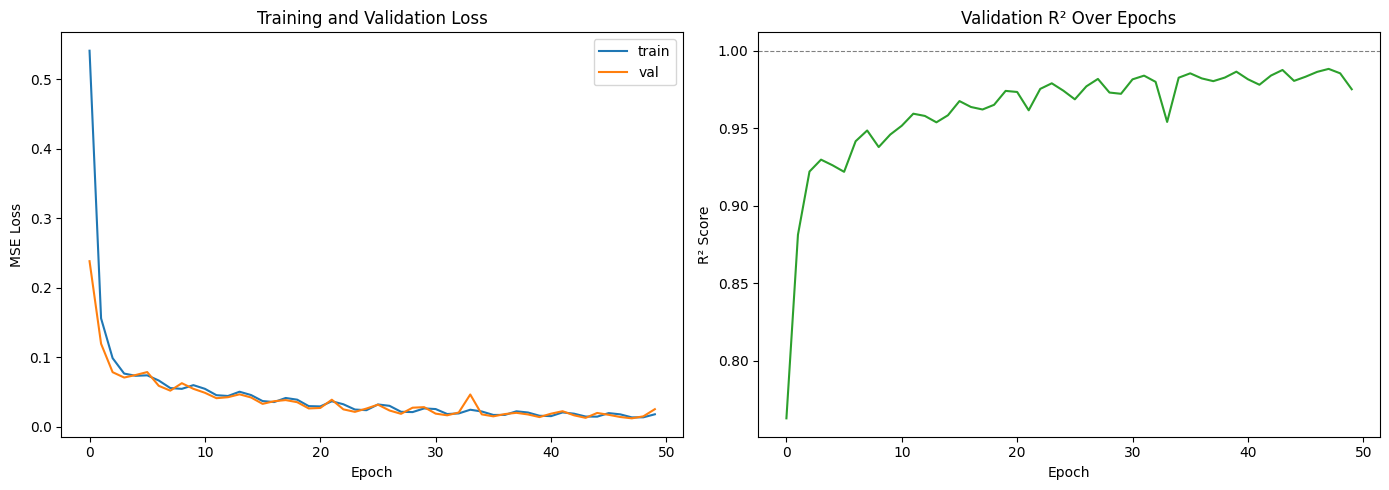

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="train")
axes[0].plot(val_losses, label="val")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()

axes[1].plot(val_r2s, color="tab:green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R² Score")
axes[1].set_title("Validation R² Over Epochs")
axes[1].axhline(1.0, color="gray", ls="--", lw=0.8)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [ ]:
model.eval()
all_preds, all_true = [], []

with torch.no_grad():
    for x_seq, x_aux, y in test_loader:
        x_seq, x_aux = x_seq.to(device), x_aux.to(device)
        pred = model(x_seq, x_aux)
        all_preds.append(pred.cpu().numpy())
        all_true.append(y.numpy())

all_preds = np.vstack(all_preds)
all_true = np.vstack(all_true)

# un-normalize back to real units
preds_real = all_preds * target_std + target_mean
true_real = all_true * target_std + target_mean

print("Overall test R2:", r2_score(all_true, all_preds))
print()
for i, name in enumerate(target_names):
    r2_i = r2_score(true_real[:, i], preds_real[:, i])
    print(f"{name:10s}: R2 = {r2_i:.4f}")

Overall test R2: 0.9742444157600403

T         : R2 = 0.9980
log_Met   : R2 = 0.9776
C_to_O    : R2 = 0.9472


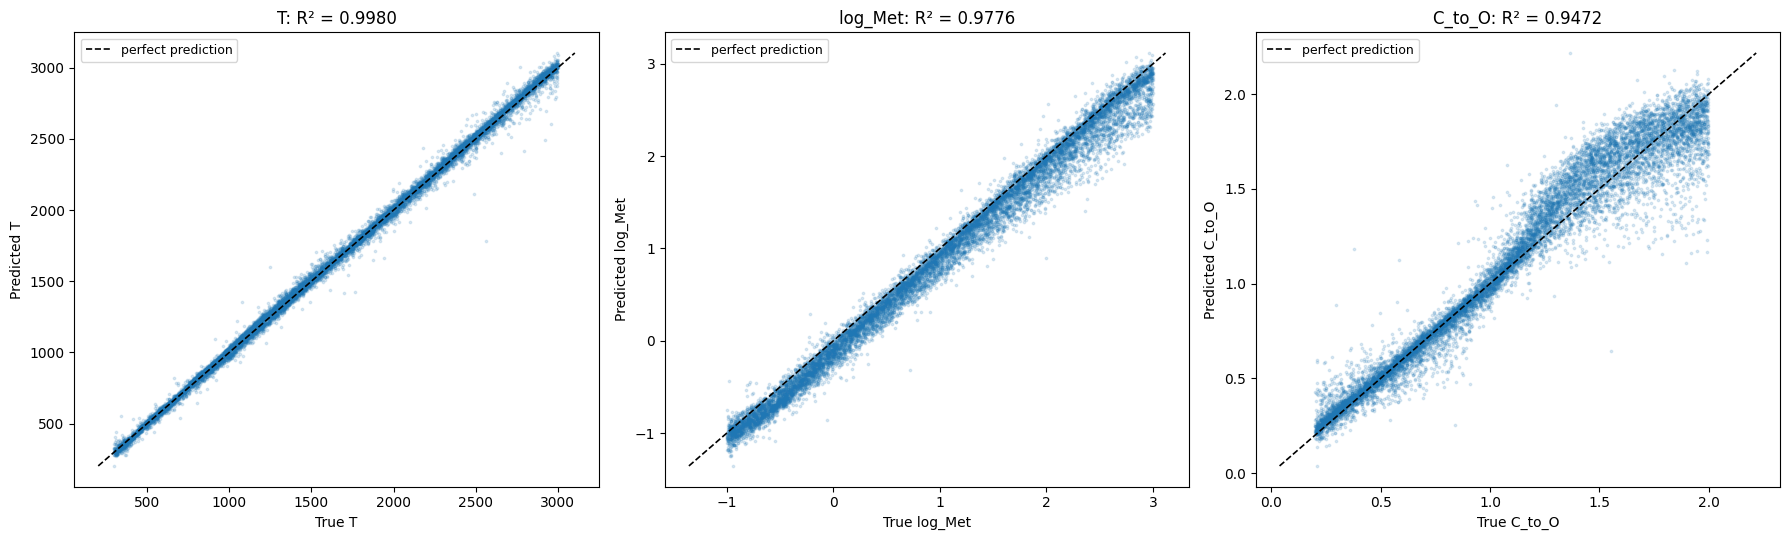

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for i, name in enumerate(target_names):
    ax = axes[i]
    true_i = true_real[:, i]
    pred_i = preds_real[:, i]

    ax.scatter(true_i, pred_i, s=3, alpha=0.15, color="tab:blue")

    lo = min(true_i.min(), pred_i.min())
    hi = max(true_i.max(), pred_i.max())
    ax.plot([lo, hi], [lo, hi], color="black", ls="--", lw=1.2, label="perfect prediction")

    r2_i = r2_score(true_i, pred_i)
    ax.set_xlabel(f"True {name}")
    ax.set_ylabel(f"Predicted {name}")
    ax.set_title(f"{name}: R² = {r2_i:.4f}")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("test_true_vs_pred.png", dpi=150)
plt.show()